# Project Title: College Tuition & Affordability Analysis in the United States

## Project Overview
This project investigates college tuition costs and how they vary across institutions in the United States. The primary objective is to help prospective students, parents, and policymakers—better understand the cost of higher education and identify major patterns in college affordability.

## Key Research Areas & Project Goals
1. **Sector Variations**: Compare tuition structures across public and private (nonprofit and for-profit) colleges.
2. **In-State vs. Out-of-State Premium**: Examine differences between in-state and out-of-state costs across various institutions.
3. **Affordability and Value**: Explore how tuition costs relate to practical postgraduate outcomes, specifically student graduation debt levels and median earnings 10 years after entry.

By building a highly optimized, light-weight dataset, this notebook serves as the core data preparation and exploratory phase for our final interactive dashboard.

In [ ]:
import pandas as pd
import numpy as np

# TODO: Replace with your actual data path (e.g., 'data.csv', or a URL)
data_path = 'Most-Recent-Cohorts-Institution.csv'

# Load the dataset into a pandas DataFrame
try:
    df = pd.read_csv(data_path)
    print("Dataset loaded successfully!")
except Exception as e:
    print(f"Could not load dataset automatically. Please update 'data_path' and try again.\nError: {e}")

/tmp/ipykernel_6724/3852248191.py:9: DtypeWarning: Columns (9,1433,1447,1475,1537,1540,1542,1606,1608,1614,1615,1619,1620,1621,1622,1623,1624,1625,1626,1627,1628,1629,1725,1726,1727,1728,1729,1743,1815,1816,1817,1818,1823,1824,1830,1831,1879,1880,1881,1882,1883,1884,1885,1886,1887,1888,1889,1890,1891,1892,1893,1894,1895,1896,1897,1898,1909,1910,1911,1912,1913,1957,1958,1959,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1983,1984,2376,2377,2403,2404,2495,2496,2497,2498,2499,2500,2501,2502,2503,2504,2505,2506,2507,2508,2509,2510,2511,2512,2513,2514,2515,2516,2517,2518,2519,2520,2521,2522,2523,2524,2525,2526,2527,2528,2529,2530,3215,3231,3235,3236) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path)


Dataset loaded successfully!


In [ ]:
# Inspect DataFrame structure and general metadata
if 'df' in locals():
    print(f"DataFrame Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
    print("--- Info ---")
    df.info()

    print("\n--- Missing Values ---")
    missing_counts = df.isnull().sum()
    display(missing_counts[missing_counts > 0])

    print("\n--- First 5 Rows ---")
    display(df.head())

DataFrame Shape: 6278 rows, 3379 columns

--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6278 entries, 0 to 6277
Columns: 3379 entries, UNITID to IN_STATE_INC3_P10
dtypes: float64(868), int64(16), object(2495)
memory usage: 161.8+ MB

--- Missing Values ---


,0
OPEID,21
OPEID6,21
ACCREDAGENCY,170
INSTURL,10
NPCURL,500
...,...
COUNT_NWNE_INC3_P10,362
IN_STATE_P10,362
IN_STATE_INC1_P10,362
IN_STATE_INC2_P10,362



--- First 5 Rows ---


,UNITID,OPEID,OPEID6,INSTNM,CITY,STABBR,ZIP,ACCREDAGENCY,INSTURL,NPCURL,...,GT_THRESHOLD_INC1_P10,GT_THRESHOLD_INC2_P10,GT_THRESHOLD_INC3_P10,COUNT_NWNE_INC1_P10,COUNT_NWNE_INC2_P10,COUNT_NWNE_INC3_P10,IN_STATE_P10,IN_STATE_INC1_P10,IN_STATE_INC2_P10,IN_STATE_INC3_P10
0,100654,100200.0,1002.0,Alabama A & M University,Normal,AL,35762,Southern Association of Colleges and Schools C...,www.aamu.edu/,www.aamu.edu/admissions-aid/tuition-fees/net-p...,...,0.5691,0.6909,0.6714,110,38,11,929,647,208,71
1,100663,105200.0,1052.0,University of Alabama at Birmingham,Birmingham,AL,35294-0110,Southern Association of Colleges and Schools C...,https://www.uab.edu/,https://tcc.ruffalonl.com/University of Alabam...,...,0.7464,0.8217,0.8495,178,84,58,2802,1299,834,667
2,100690,2503400.0,25034.0,Amridge University,Montgomery,AL,36117-3553,Southern Association of Colleges and Schools C...,https://www.amridgeuniversity.edu/,https://www2.amridgeuniversity.edu:9091/,...,PS,PS,PS,PS,PS,PS,158,PS,PS,PS
3,100706,105500.0,1055.0,University of Alabama in Huntsville,Huntsville,AL,35899,Southern Association of Colleges and Schools C...,www.uah.edu/,uah.clearcostcalculator.com/student/default/ne...,...,0.7946,0.8714,0.8468,91,40,26,1271,584,351,335
4,100724,100500.0,1005.0,Alabama State University,Montgomery,AL,36104-0271,Southern Association of Colleges and Schools C...,www.alasu.edu/,tcc.ruffalonl.com/Alabama State University/Fre...,...,0.5696,0.6627,0.7073,163,45,5,1343,989,289,69


### Step B. Prepare and Explore the Data
We will select a targeted set of key columns from this massive 3,379-column College Scorecard dataset to address our primary project goals.

Our analysis will focus specifically on:
1. **Comparing Tuition costs**: In-state (`TUITIONFEE_IN`) vs. Out-of-state (`TUITIONFEE_OUT`).
2. **Institutional Characteristics**: Comparing Public vs. Private sectors (`CONTROL`).
3. **Affordability and Value**: Analyzing the balance between student enrollment size (`UGDS`), graduation debt (`GRAD_DEBT_MDN_SUPP`), and post-graduate earnings (`MD_EARN_WNE_P10`).

In [ ]:
# Select a representative subset of columns to clean and analyze
columns_of_interest = [
    'UNITID', 'INSTNM', 'STABBR', 'CONTROL', 'PREDDEG',
    'ADM_RATE', 'UGDS', 'TUITIONFEE_IN', 'TUITIONFEE_OUT',
    'MD_EARN_WNE_P10', 'GRAD_DEBT_MDN_SUPP'
]

# Create a working subset
df_clean = df[columns_of_interest].copy()

# Inspect data types and missing values in this subset
print("Subset info:")
display(df_clean.info())
print("\nMissing values count per selected column:")
display(df_clean.isnull().sum())

Subset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6278 entries, 0 to 6277
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   UNITID              6278 non-null   int64  
 1   INSTNM              6278 non-null   object 
 2   STABBR              6278 non-null   object 
 3   CONTROL             6278 non-null   int64  
 4   PREDDEG             6278 non-null   int64  
 5   ADM_RATE            1912 non-null   float64
 6   UGDS                5483 non-null   float64
 7   TUITIONFEE_IN       3646 non-null   float64
 8   TUITIONFEE_OUT      3646 non-null   float64
 9   MD_EARN_WNE_P10     5916 non-null   object 
 10  GRAD_DEBT_MDN_SUPP  5552 non-null   object 
dtypes: float64(4), int64(3), object(4)
memory usage: 539.6+ KB


None


Missing values count per selected column:


,0
UNITID,0
INSTNM,0
STABBR,0
CONTROL,0
PREDDEG,0
ADM_RATE,4366
UGDS,795
TUITIONFEE_IN,2632
TUITIONFEE_OUT,2632
MD_EARN_WNE_P10,362


### Cleaning and Type Conversions
Many numeric columns in the College Scorecard dataset contain string placeholders like `'PrivacySuppressed'` (or similar flags) or are read as objects. We will convert these columns to numeric, forcing non-numeric strings to `NaN`.

In [ ]:
# Convert Control and Predominant Degree to categorical/readable values
control_map = {1: 'Public', 2: 'Private Nonprofit', 3: 'Private For-Profit'}
preddeg_map = {0: 'Not classified', 1: 'Certificate', 2: 'Associate', 3: 'Bachelor', 4: 'Entirely Graduate'}

df_clean['CONTROL'] = df_clean['CONTROL'].map(control_map)
df_clean['PREDDEG'] = df_clean['PREDDEG'].map(preddeg_map)

# Coerce numeric columns that might have string placeholders or mixed types to float
numeric_cols = ['ADM_RATE', 'UGDS', 'TUITIONFEE_IN', 'TUITIONFEE_OUT', 'MD_EARN_WNE_P10', 'GRAD_DEBT_MDN_SUPP']
for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# Summary statistics of cleaned numeric features
display(df_clean.describe())

,UNITID,ADM_RATE,UGDS,TUITIONFEE_IN,TUITIONFEE_OUT,MD_EARN_WNE_P10,GRAD_DEBT_MDN_SUPP
count,6.278000e+03,1912.000000,5483.000000,3646.000000,3646.000000,5293.000000,4672.000000
mean,2.245872e+06,0.727765,2638.776035,18307.224081,21846.165661,48622.265634,15454.342894
std,7.814389e+06,0.231256,6524.368609,17528.372592,16573.961760,17681.075933,7216.703828
min,1.006540e+05,0.000000,0.000000,0.000000,0.000000,14374.000000,0.000000
25%,1.743890e+05,0.612450,127.000000,5898.500000,9952.000000,36421.000000,9500.000000
50%,2.297180e+05,0.779400,563.000000,12081.000000,16449.000000,45562.000000,13569.000000
75%,4.599805e+05,0.905300,2219.000000,24275.000000,29207.500000,57608.000000,21500.000000
max,4.966450e+07,1.000000,163164.000000,273276.000000,273276.000000,166642.000000,42378.000000


### Aggregating and Analyzing Trends
 Grouped aggregations using `groupby()` to explore relationship patterns like how tuition fees and earnings compare across different types of institution control (Public vs Private) and predominant degrees.

In [ ]:
# Group by institution type (CONTROL) and look at averages
summary_by_control = df_clean.groupby('CONTROL').agg(
    institution_count=('UNITID', 'count'),
    avg_enrollment=('UGDS', 'mean'),
    avg_in_state_tuition=('TUITIONFEE_IN', 'mean'),
    median_earnings_10yr=('MD_EARN_WNE_P10', 'median'),
    median_grad_debt=('GRAD_DEBT_MDN_SUPP', 'median')
).reset_index()

display(summary_by_control)

,CONTROL,institution_count,avg_enrollment,avg_in_state_tuition,median_earnings_10yr,median_grad_debt
0,Private For-Profit,2330,495.095817,17831.349495,34658.0,9525.0
1,Private Nonprofit,1901,1856.717349,31904.584308,57332.0,22500.0
2,Public,2047,5610.701271,6810.518257,47011.0,13117.0


## Step C. Develop and Interpret Visualizations

We will create three key visualizations to help understand relationships within our data to investigate college tuition and affordability patterns:
1. **In-State vs. Out-of-State Tuition Fees**: To directly analyze the pricing premium charged to out-of-state students across different sectors.
2. **Distribution of Tuition Costs by School Sector**: To explore how tuition fees vary between Public, Private Nonprofit, and Private For-Profit institutions.
3. **Tuition Investment vs. Post-Graduate Earnings**: To explore if higher tuition translates directly to higher post-graduate financial outcomes.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

### Chart 1: Distribution of 10-Year Median Earnings by School Control Sector
This boxplot shows the spread, median, and outliers of median student earnings 10 years after entry for each institutional control category.

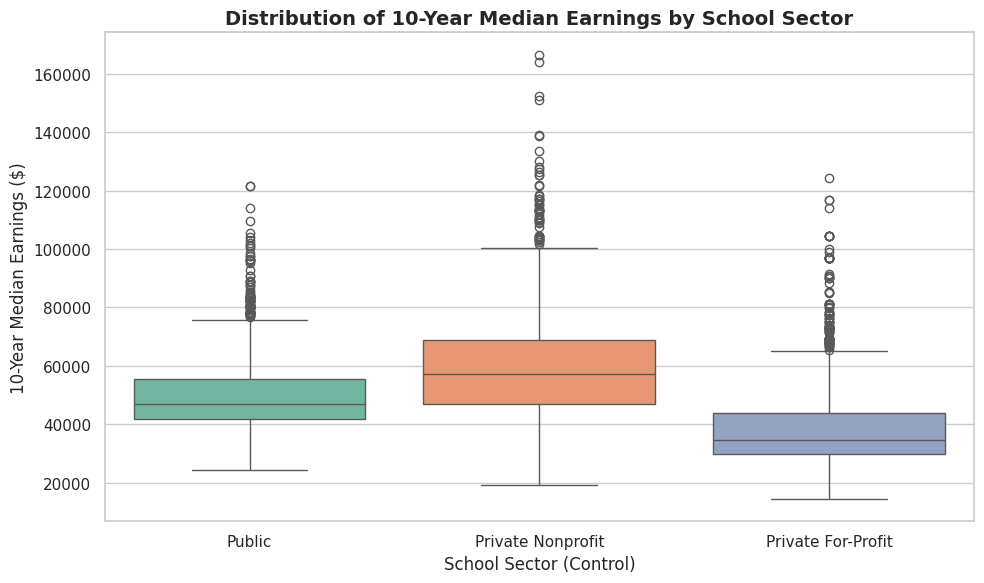

In [ ]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=df_clean.dropna(subset=['MD_EARN_WNE_P10', 'CONTROL']),
    x='CONTROL',
    y='MD_EARN_WNE_P10',
    palette='Set2',
    hue='CONTROL',
    legend=False
)
plt.title('Distribution of 10-Year Median Earnings by School Sector', fontsize=14, fontweight='bold')
plt.xlabel('School Sector (Control)', fontsize=12)
plt.ylabel('10-Year Median Earnings ($)', fontsize=12)
plt.tight_layout()
plt.show()

### Chart 2: Cost of Attendance vs. Post-Graduate Earnings
This scatter plot explores the relationship between in-state tuition fees and median earnings 10 years after enrollment, color-coded by the school control type.

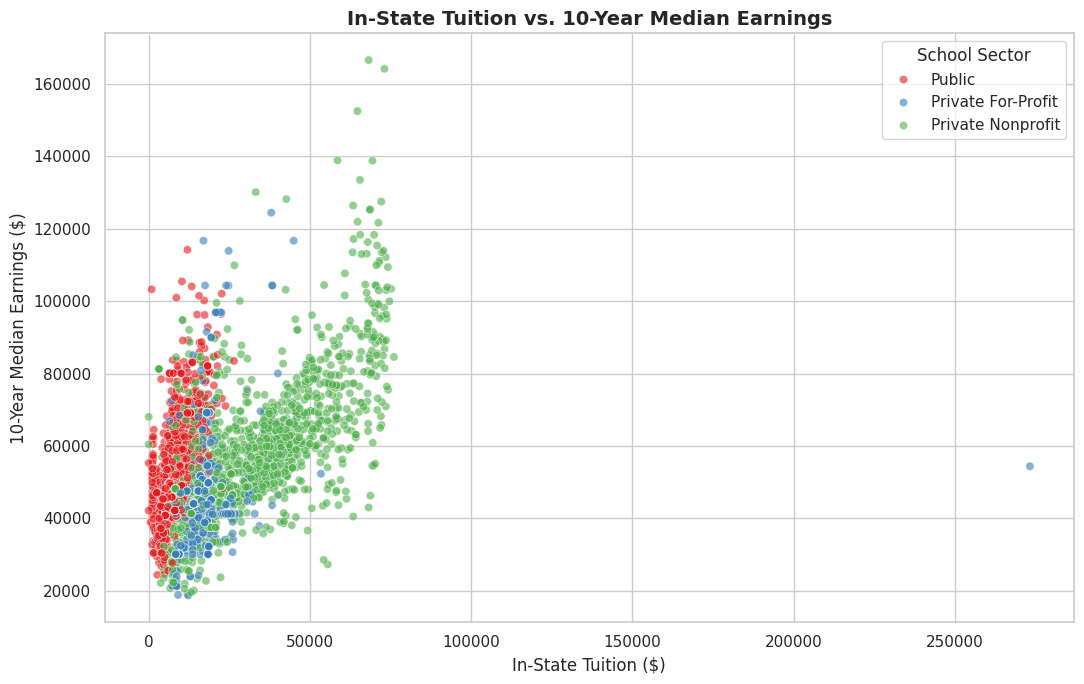

In [ ]:
plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df_clean.dropna(subset=['TUITIONFEE_IN', 'MD_EARN_WNE_P10']),
    x='TUITIONFEE_IN',
    y='MD_EARN_WNE_P10',
    hue='CONTROL',
    alpha=0.6,
    palette='Set1'
)
plt.title('In-State Tuition vs. 10-Year Median Earnings', fontsize=14, fontweight='bold')
plt.xlabel('In-State Tuition ($)', fontsize=12)
plt.ylabel('10-Year Median Earnings ($)', fontsize=12)
plt.legend(title='School Sector')
plt.tight_layout()
plt.show()

### Chart 3: Median Earnings vs. Median Student Debt by Predominant Degree Type
This bar chart aggregates and contrasts the median earnings 10 years post-entry against the median student graduation debt, grouped by the predominant degree offered by the institution.

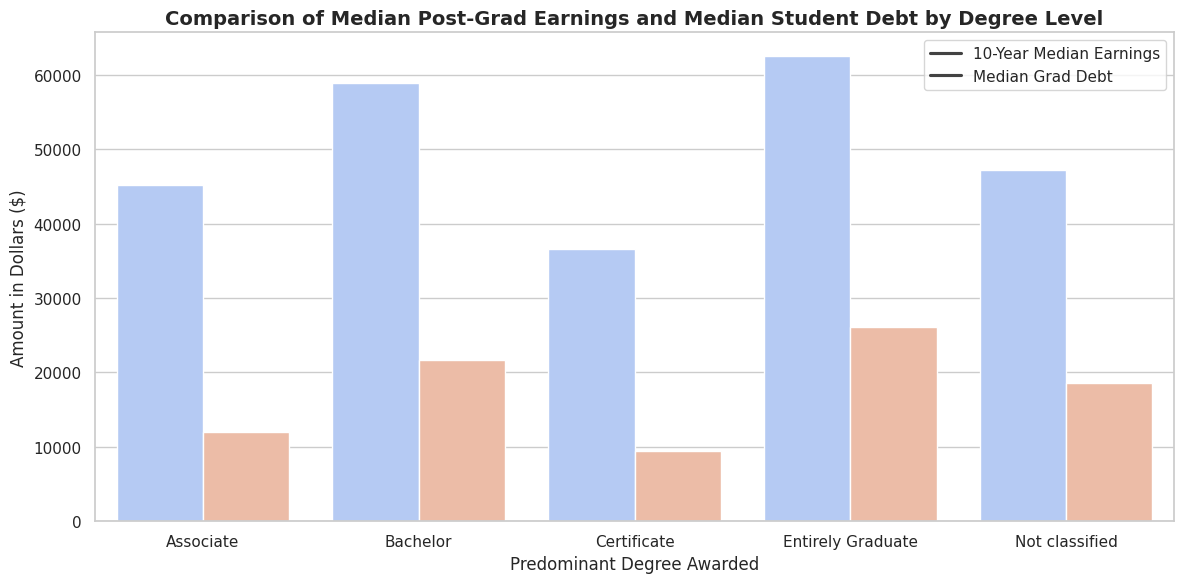

In [ ]:
# Group by predominant degree and calculate the median of both earnings and debt
degree_summary = df_clean.groupby('PREDDEG').agg(
    median_earnings=('MD_EARN_WNE_P10', 'median'),
    median_debt=('GRAD_DEBT_MDN_SUPP', 'median')
).reset_index().dropna()

# Melt dataframe for side-by-side bar comparison
degree_melted = degree_summary.melt(id_vars='PREDDEG', value_vars=['median_earnings', 'median_debt'],
                                    var_name='Metric', value_name='Amount')

plt.figure(figsize=(12, 6))
sns.barplot(
    data=degree_melted,
    x='PREDDEG',
    y='Amount',
    hue='Metric',
    palette='coolwarm'
)
plt.title('Comparison of Median Post-Grad Earnings and Median Student Debt by Degree Level', fontsize=14, fontweight='bold')
plt.xlabel('Predominant Degree Awarded', fontsize=12)
plt.ylabel('Amount in Dollars ($)', fontsize=12)
plt.legend(labels=['10-Year Median Earnings', 'Median Grad Debt'])
plt.tight_layout()
plt.show()

### Chart 4: Average In-State vs. Out-of-State Tuition by State
This bar chart compares the average in-state and out-of-state tuition costs for each US state/territory, highlighting the tuition premium charged to non-resident students.

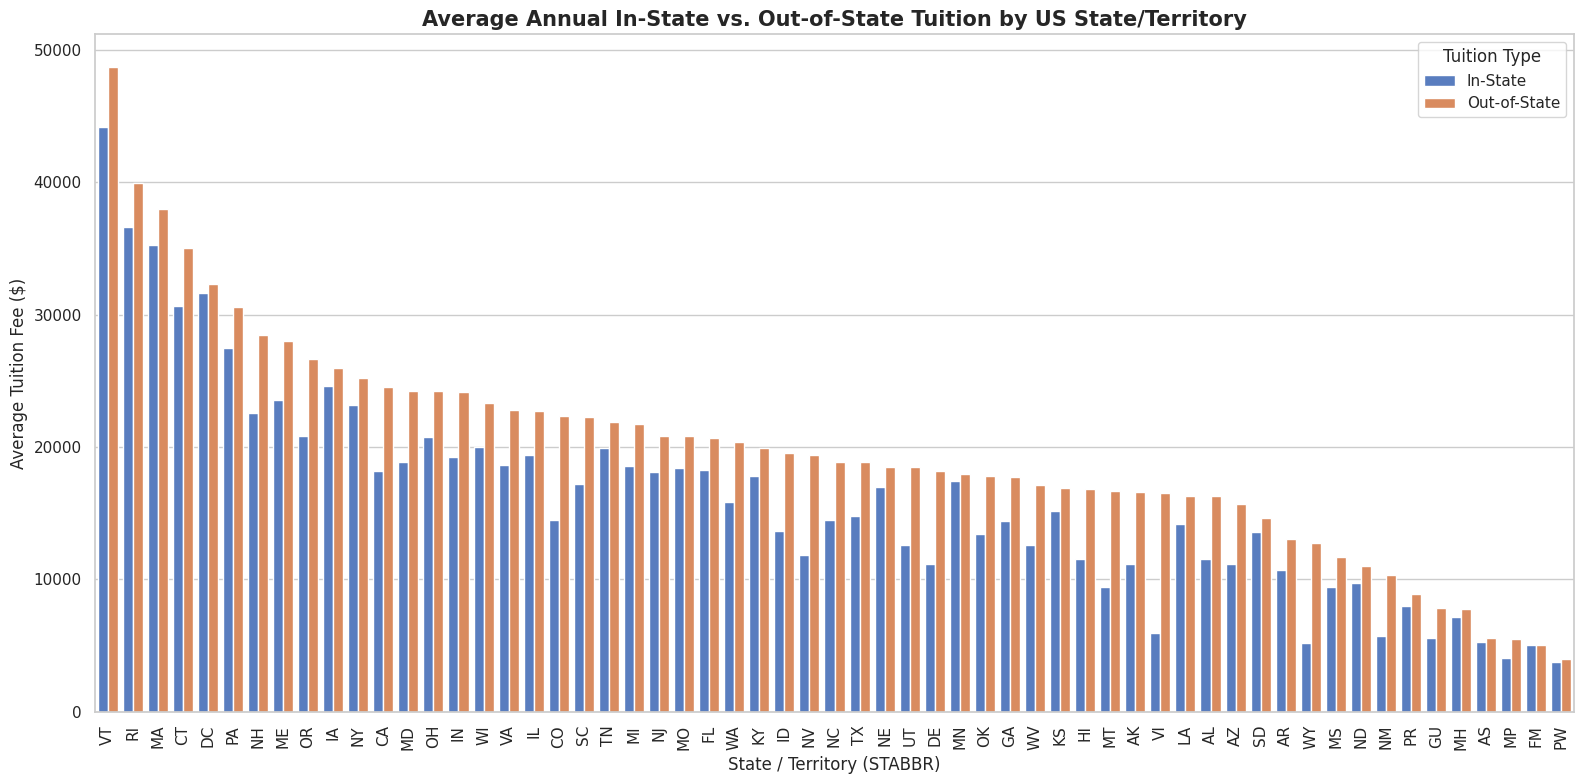

In [ ]:
# Group by state and calculate mean tuition fees
state_tuition = df_clean.groupby('STABBR')[['TUITIONFEE_IN', 'TUITIONFEE_OUT']].mean().reset_index()

# Sort by out-of-state tuition for logical visual flow
state_tuition = state_tuition.sort_values(by='TUITIONFEE_OUT', ascending=False)

# Melt the dataset to prepare for a grouped bar plot
state_melted = state_tuition.melt(id_vars='STABBR', value_vars=['TUITIONFEE_IN', 'TUITIONFEE_OUT'],
                                  var_name='Tuition Type', value_name='Average Cost')

# Map legend names to be clearer
state_melted['Tuition Type'] = state_melted['Tuition Type'].map({'TUITIONFEE_IN': 'In-State', 'TUITIONFEE_OUT': 'Out-of-State'})

# Generate the plot
plt.figure(figsize=(16, 8))
sns.barplot(
    data=state_melted,
    x='STABBR',
    y='Average Cost',
    hue='Tuition Type',
    palette='muted'
)

plt.title('Average Annual In-State vs. Out-of-State Tuition by US State/Territory', fontsize=15, fontweight='bold')
plt.xlabel('State / Territory (STABBR)', fontsize=12)
plt.ylabel('Average Tuition Fee ($)', fontsize=12)
plt.xticks(rotation=90)
plt.legend(title='Tuition Type')
plt.tight_layout()
plt.show()

##  Prepare the Dashboard Dataset

 Instead of the original 3,379 columns and 160+ MB size, we export our curated `df_clean` dataset containing only the 11 key characteristics and performance metrics.

We will also remove rows that do not have crucial outcome information (such as missing both earnings and tuition) to ensure the dashboard remains clean and focused. This file will be extremely small (well under the 25 MB threshold).

In [ ]:
# Drop rows where critical variables are completely missing
dashboard_df = df_clean.dropna(subset=['MD_EARN_WNE_P10', 'GRAD_DEBT_MDN_SUPP', 'TUITIONFEE_IN'], how='all').copy()

# Save the filtered and clean dataset to a CSV file
output_filename = 'college_scorecard_dashboard_subset.csv'
dashboard_df.to_csv(output_filename, index=False)

# Check the file size of our newly created CSV file
import os
file_size_mb = os.path.getsize(output_filename) / (1024 * 1024)
print(f"Saved: {output_filename}")
print(f"New Dataset Shape: {dashboard_df.shape[0]} rows, {dashboard_df.shape[1]} columns")
print(f"File Size: {file_size_mb:.2f} MB")

Saved: college_scorecard_dashboard_subset.csv
New Dataset Shape: 5722 rows, 11 columns
File Size: 0.54 MB
